In [1]:
import sys
import torch
import platform

print("OS:", platform.platform())
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

OS: Linux-6.6.159+-x86_64-with-glibc2.39
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA version: 13.0
CUDA available: True
GPU: Tesla T4


In [2]:
!git clone --depth 1 https://github.com/GSanShui/XPert.git /content/XPert
%cd /content/XPert

Cloning into '/content/XPert'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 65 (delta 13), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (65/65), 9.03 MiB | 15.46 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/XPert


In [3]:
from pathlib import Path

files = [
    "train_xpert.py",
    "configs/config_l1000_example.yaml",
    "processed_data/l1000_sdst_example.h5ad",
    "processed_data/PPI_gene_vector_128d.npy",
    "HG_data/saved_embedding/HG_drug_embeddings.npy"
]

for f in files:
    p = Path(f)
    print(f, "OK" if p.exists() else "MISSING")

train_xpert.py OK
configs/config_l1000_example.yaml OK
processed_data/l1000_sdst_example.h5ad OK
processed_data/PPI_gene_vector_128d.npy OK
HG_data/saved_embedding/HG_drug_embeddings.npy OK


In [4]:
%cd /content/XPert

import sys
import torch
import yaml
import h5py
from pathlib import Path

print("===== 1. Python / GPU =====")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))

print("\n===== 2. XPert configuration =====")
with open("configs/config_l1000_example.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

ds = config["dataset"]
print("UniMol path:", ds.get("drug_unimol_path"))
print("Drug SMILES path:", ds.get("drug_smi_path", "NOT CONFIGURED"))
print("Epochs:", config["train"]["num_epochs"])
print("Batch size:", config["train"]["batch_size"])

print("\n===== 3. Required files =====")
files = [
    "processed_data/l1000_sdst_example.h5ad",
    "processed_data/PPI_gene_vector_128d.npy",
    "HG_data/saved_embedding/HG_drug_embeddings.npy",
]

for file in files:
    print(file, "OK" if Path(file).is_file() else "MISSING")

print("\n===== 4. Example dataset =====")
with h5py.File(files[0], "r") as f:
    print("Top-level fields:", list(f.keys()))
    print("Metadata fields:",
          list(f["obs"].keys()) if "obs" in f else "NOT FOUND")
    print("Control expression:",
          "X_ctl" in f["obsm"] if "obsm" in f else False)

/content/XPert
===== 1. Python / GPU =====
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU capability: (7, 5)

===== 2. XPert configuration =====
UniMol path: None
Drug SMILES path: NOT CONFIGURED
Epochs: 10
Batch size: 2

===== 3. Required files =====
processed_data/l1000_sdst_example.h5ad OK
processed_data/PPI_gene_vector_128d.npy OK
HG_data/saved_embedding/HG_drug_embeddings.npy OK

===== 4. Example dataset =====
Top-level fields: ['X', 'layers', 'obs', 'obsm', 'obsp', 'uns', 'var', 'varm', 'varp']
Metadata fields: ['bead_batch', 'build_name', 'cell_drug_dose_time', 'cell_idx', 'cell_iname', 'cell_mfc_name', 'cell_pert_dose_time', 'cmap_name', 'count_cv', 'count_mean', 'det_plate', 'det_well', 'dyn_range', 'failure_mode', 'inv_level_10', 'n_replicates', 'nearest_dose', 'pert_dose', 'pert_dose_unit', 'pert_id', 'pert_idose', 'pert_idx', 'pert_itime', 'pert_mfc_id', 'pert_time', 'pert_time_unit', 'pert_type', 'project_code', 'qc_f_logp', 'qc_iqr', 'qc_pass

In [5]:
%cd /content/XPert
%pip -q install anndata

/content/XPert
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [6]:
import anndata as ad
import numpy as np
import pandas as pd
from pathlib import Path

adata = ad.read_h5ad(
    "processed_data/l1000_sdst_example.h5ad"
)

print("===== Dataset information =====")
print("Number of samples:", adata.n_obs)
print("Number of genes:", adata.n_vars)

print("\n===== Data split =====")
print(adata.obs["split_1"].value_counts())

print("\n===== Drugs =====")
print("Number of unique drug IDs:",
      adata.obs["pert_idx"].nunique())

print("\n===== Additional information =====")
print("uns keys:", list(adata.uns.keys()))
print("obsm keys:", list(adata.obsm.keys()))

print("\n===== Drug feature files =====")
for name in [
    "processed_data/all_drugs_unimol_arr.npy",
    "processed_data/all_drugs_idx2smi_8981.npy",
]:
    print(name, Path(name).exists())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


===== Dataset information =====
Number of samples: 30
Number of genes: 978

===== Data split =====
split_1
train    25
test      5
Name: count, dtype: int64

===== Drugs =====
Number of unique drug IDs: 5

===== Additional information =====
uns keys: []
obsm keys: ['X_ctl']

===== Drug feature files =====
processed_data/all_drugs_unimol_arr.npy False
processed_data/all_drugs_idx2smi_8981.npy False


In [7]:
import numpy as np
import pandas as pd
from scipy import sparse
from pathlib import Path

# 只使用独立测试集
test_mask = (
    adata.obs["split_1"]
    .astype(str)
    .str.lower()
    .eq("test")
    .to_numpy()
)

assert test_mask.sum() > 0, "No test samples found!"

def to_dense(x):
    if sparse.issparse(x):
        return x.toarray()
    return np.asarray(x)

# 真实药物处理后的表达
y_true = to_dense(adata.X[test_mask]).astype("float32")

# No-change预测：直接使用处理前的表达
y_pred = to_dense(
    adata.obsm["X_ctl"][test_mask]
).astype("float32")

assert y_true.shape == y_pred.shape

# 计算评价指标
mse = np.mean((y_true - y_pred) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_true - y_pred))

results = pd.DataFrame([{
    "Model": "No-change Baseline",
    "Samples": len(y_true),
    "Genes": y_true.shape[1],
    "MSE": float(mse),
    "RMSE": float(rmse),
    "MAE": float(mae)
}])

print("===== Baseline Results =====")
print(results.to_string(index=False))

# 保存结果
output_dir = Path("experiment/course_project")
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    output_dir / "baseline_results.csv",
    index=False
)

print("\nBaseline results saved!")

===== Baseline Results =====
             Model  Samples  Genes     MSE     RMSE      MAE
No-change Baseline        5    978 0.41843 0.646861 0.395882

Baseline results saved!


In [8]:
from google.colab import files

files.download(
    "/content/XPert/experiment/course_project/baseline_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
%pip install -q "pandas==2.2.3" "bottleneck>=1.5.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
anndata 0.13.4 requires pandas>=2.3, but you have pandas 2.2.3 which is incompatible.


In [10]:
%pip install -q "pandas==2.2.3" "anndata==0.12.7" "bottleneck>=1.5.0"

In [1]:
import pandas as pd
import anndata as ad
from pathlib import Path

print("Pandas:", pd.__version__)
print("AnnData:", ad.__version__)

adata = ad.read_h5ad(
    "/content/XPert/processed_data/l1000_sdst_example.h5ad"
)

print("Dataset shape:", adata.shape)
print("Dataset loaded successfully!")

print(
    "Baseline CSV exists:",
    Path("/content/XPert/experiment/course_project/baseline_results.csv").exists()
)

Pandas: 2.2.3
AnnData: 0.12.7


/tmp/ipykernel_6790/2916598146.py:6: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("AnnData:", ad.__version__)


Dataset shape: (30, 978)
Dataset loaded successfully!
Baseline CSV exists: True


In [2]:
%cd /content/XPert

import anndata as ad
import numpy as np
from pathlib import Path

# 重新读取原始示例数据
adata = ad.read_h5ad(
    "processed_data/l1000_sdst_example.h5ad"
)

# 复制官方数据划分
original_split = adata.obs["split_1"].astype(str).to_numpy()
new_split = original_split.copy()

# 从训练集中随机抽取5个验证样本
rng = np.random.default_rng(2026)
train_indices = np.where(original_split == "train")[0]

valid_indices = rng.choice(
    train_indices,
    size=5,
    replace=False
)

new_split[valid_indices] = "valid"

# 保存为新的一列
adata.obs["split_course"] = new_split

# 确保原来的测试集没有改变
assert np.array_equal(
    original_split == "test",
    new_split == "test"
)

print("===== New Data Split =====")
print(adata.obs["split_course"].value_counts())

# 保存新数据，不覆盖官方原始数据
output_path = Path(
    "processed_data/l1000_sdst_course.h5ad"
)

adata.write_h5ad(output_path)

print("\nSaved:", output_path)

/content/XPert
===== New Data Split =====
split_course
train    20
test      5
valid     5
Name: count, dtype: int64

Saved: processed_data/l1000_sdst_course.h5ad


In [3]:
print("===== Drug Information =====")

drug_info = (
    adata.obs[
        ["pert_idx", "pert_id", "cmap_name"]
    ]
    .drop_duplicates()
    .sort_values("pert_idx")
)

print(drug_info.to_string(index=False))

print("\nNumber of unique drugs:")
print(adata.obs["pert_idx"].nunique())

print("\n===== GPU Check =====")

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

===== Drug Information =====
 pert_idx       pert_id     cmap_name
        0 BRD-K06817181 BRD-K06817181
        1 BRD-K97118047 BRD-K97118047
        2 BRD-K68264559   brimonidine
        3 BRD-A83255679 BRD-A83255679
        4 BRD-K68020183 BRD-K68020183

Number of unique drugs:
5

===== GPU Check =====
CUDA available: True
GPU: Tesla T4


In [4]:
%cd /content/XPert

from pathlib import Path
import numpy as np
import yaml
import shutil
import anndata as ad

root = Path("/content/XPert")
backup = root / "experiment/course_project/source_backup"
backup.mkdir(parents=True, exist_ok=True)

# 1. 检查真实知识图谱特征
adata = ad.read_h5ad(
    root / "processed_data/l1000_sdst_course.h5ad"
)

hg = np.load(
    root / "HG_data/saved_embedding/HG_drug_embeddings.npy"
)

n_drugs = int(adata.obs["pert_idx"].max()) + 1

assert hg.ndim == 2
assert hg.shape[0] >= n_drugs
assert hg.shape[1] == 256

print("HG embeddings:", hg.shape)
print("Drugs in example:", n_drugs)

# 2. 创建仅用于满足输入接口的占位数组
# 注意：这些不是真实 UniMol 特征。
# wo_unimol=True 时，模型只保留真实 HG 药物嵌入。
placeholder = np.zeros((n_drugs, 2, 514), dtype=np.float32)
placeholder[:, 0, 0] = 1

np.save(
    root / "processed_data/course_hg_only_placeholder.npy",
    placeholder
)

# 3. 创建独立配置文件
with open(root / "configs/config_l1000_example.yaml") as f:
    cfg = yaml.safe_load(f)

cfg["dataset"]["drug_unimol_path"] = (
    "processed_data/course_hg_only_placeholder.npy"
)
cfg["dataset"]["max_atom_size"] = 2
cfg["train"]["batch_size"] = 1
cfg["train"]["num_epochs"] = 10

with open(
    root / "configs/config_l1000_course_hg.yaml", "w"
) as f:
    yaml.safe_dump(cfg, f)

# 4. 安全修改源代码，保留原始备份
def patch_file(filename, replacements):
    p = root / filename
    b = backup / p.name

    if not b.exists():
        shutil.copy2(p, b)

    source = p.read_text(encoding="utf-8")

    for old, new in replacements:
        if old in source:
            source = source.replace(old, new)
        elif new not in source:
            raise RuntimeError(
                f"Source pattern not found in {filename}: {old[:60]}"
            )

    p.write_text(source, encoding="utf-8")
    print("Patched:", filename)

# 使用已安装的 AnnData 读取 h5ad；
# HG-only 路径不调用 UniMolRepr。
patch_file("utils.py", [
    ("import scanpy as sc", "import anndata as sc"),
    ("from unimol_tools import UniMolRepr",
     "UniMolRepr = None  # Not used in HG-only experiment"),
    ("num_workers=10", "num_workers=0")
])

# 移除模型中未使用的 PyG 导入
patch_file("models/model_XPert.py", [
    ("from torch_geometric.nn import HeteroConv, SAGEConv",
     "# Unused torch_geometric import omitted for HG-only demo")
])

# T4兼容的注意力实现
replacement = '''
def flash_attn_func(q, k, v, dropout_p=0.0):
    return torch.nn.functional.scaled_dot_product_attention(
        q.transpose(1, 2),
        k.transpose(1, 2),
        v.transpose(1, 2),
        dropout_p=dropout_p,
        is_causal=False
    ).transpose(1, 2).contiguous()
'''

patch_file("models/model_utils.py", [
    ("from flash_attn.flash_attn_interface import flash_attn_func",
     replacement.strip())
])

# 修复CPU/非混合精度分支的返回值解包；
# 测试指标不能被验证指标覆盖。
patch_file("train_xpert.py", [
    (
        "trt_output, ctl_output, deg_output, trt_raw_data, ctl_raw_data, _ = model(data)",
        "trt_output, ctl_output, deg_output, trt_raw_data, ctl_raw_data, _, cell_class_true, cell_class_predict = model(data)"
    ),
    (
        "            test_metrics = val_metrics",
        "            # Keep independently computed test metrics"
    ),
    (
        "validate(model, test_dataloader, args, config, flag=True, scaler=gradscaler)",
        "validate(best_model, test_dataloader, args, config, flag=True, scaler=gradscaler)"
    )
])

print("\nHG-only preparation completed!")

/content/XPert
HG embeddings: (8981, 256)
Drugs in example: 5
Patched: utils.py
Patched: models/model_XPert.py
Patched: models/model_utils.py
Patched: train_xpert.py

HG-only preparation completed!


In [5]:
%cd /content/XPert

import torch
import yaml

from models.model_XPert import XPertNet
from datasets.MyDataset import MyDataset
from utils import load_dataloader

with open("configs/config_l1000_course_hg.yaml") as f:
    cfg = yaml.safe_load(f)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Configured drug feature:",
      cfg["dataset"]["drug_unimol_path"])

print("\nXPert model imports successfully!")

/content/XPert


ModuleNotFoundError: No module named 'datasets.MyDataset'

In [6]:
%cd /content/XPert

from pathlib import Path
import sys
import importlib

# 检查官方数据集文件
dataset_file = Path("datasets/MyDataset.py")

print("Dataset file exists:", dataset_file.exists())

if dataset_file.exists():
    # 将本地 datasets 文件夹标记为 Python 包
    Path("datasets/__init__.py").touch(exist_ok=True)

    # 确保当前项目排在导入搜索路径前面
    project_path = str(Path.cwd())
    if project_path in sys.path:
        sys.path.remove(project_path)
    sys.path.insert(0, project_path)

    # 清除可能已加载的同名第三方包
    sys.modules.pop("datasets", None)
    importlib.invalidate_caches()

    # 重新测试导入
    from datasets.MyDataset import MyDataset

    print("MyDataset imported successfully!")
else:
    print("MyDataset.py is missing. Check the datasets folder.")

/content/XPert
Dataset file exists: True
MyDataset imported successfully!


In [7]:
%cd /content/XPert

from models.model_XPert import XPertNet
from datasets.MyDataset import MyDataset
from utils import load_dataloader

print("===== Import Check =====")
print("XPertNet: OK")
print("MyDataset: OK")
print("load_dataloader: OK")

print("\nAll core modules imported successfully!")

/content/XPert
===== Import Check =====
XPertNet: OK
MyDataset: OK
load_dataloader: OK

All core modules imported successfully!


In [8]:
%cd /content/XPert

import torch
import yaml
import logging
from types import SimpleNamespace

from utils import load_dataloader
from models.model_XPert import XPertNet

# 1. 读取我们之前创建的配置
with open("configs/config_l1000_course_hg.yaml", "r") as f:
    config = yaml.safe_load(f)

# 2. 配置 XPert-HG-only 实验参数
args = SimpleNamespace(
    model="XPert",
    dataset="l1000_sdst_course",
    drug_feat="unimol",
    pretrained_mode="global",
    mode="train",

    include_cell_idx=True,
    wo_HG=False,
    wo_atom=False,
    wo_atom_HG=False,
    wo_unimol=True,
    wo_ppi=False,
    use_gene_pos_emed=False,

    output_attention=False,
    output_cls_embed=False
)

logger = logging.getLogger("xpert_course")
logger.setLevel(logging.INFO)

device = torch.device("cuda:0")

# 3. 加载训练、验证和测试数据
train_loader, val_loader, test_loader, data = load_dataloader(
    args,
    config,
    logger,
    nfold="split_course",
    return_rawdata=True
)

print("===== DataLoader =====")
print("Train samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Test samples:", len(test_loader.dataset))

# 4. 获取一个训练批次
batch = next(iter(train_loader))

print("\n===== Batch shapes =====")
for i, x in enumerate(batch):
    print(f"Input {i}: {tuple(x.shape)}")

# 5. 创建 XPert 模型
model = XPertNet(args, config, device, logger)
model.init_weights()
model = model.to(device)
model.eval()

print("\n===== Model =====")
print("Device:", device)

# 6. 执行一次真实的前向传播
with torch.no_grad():
    outputs = model(batch)

treated_pred = outputs[2] + outputs[4]
treated_true = outputs[3]

print("\n===== Forward Pass =====")
print("Output tensors:", len(outputs))
print("Predicted expression:", treated_pred.shape)
print("True expression:", treated_true.shape)

assert treated_pred.shape == treated_true.shape
assert torch.isfinite(treated_pred).all()

print("\nXPert Forward Pass SUCCESS!")

/content/XPert


INFO:xpert_course:Using 2 atom
INFO:xpert_course:train data:20
INFO:xpert_course:Valid data:5
INFO:xpert_course:Test data:5
INFO:xpert_course:For dataset l1000_sdst_course, max_value:15.002, min_value:0.0
INFO:xpert_course:Starting load train data...
INFO:xpert_course:binning process... n_bins:128
100%|██████████| 20/20 [00:00<00:00, 684.33it/s]
INFO:xpert_course:Starting load valid data...
INFO:xpert_course:binning process... n_bins:128
100%|██████████| 5/5 [00:00<00:00, 1084.86it/s]
INFO:xpert_course:Starting load test data...
INFO:xpert_course:binning process... n_bins:128
100%|██████████| 5/5 [00:00<00:00, 971.94it/s]
INFO:xpert_course:train dataloader:20
INFO:xpert_course:Valid dataloader:5
INFO:xpert_course:Test dataloader:5
INFO:xpert_course:For cell embedding: using ppi_gene_vector + exp embedding


===== DataLoader =====
Train samples: 20
Validation samples: 5
Test samples: 5

===== Batch shapes =====
Input 0: (1, 978)
Input 1: (1, 978)
Input 2: (1, 978)
Input 3: (1, 978)
Input 4: (1, 2, 514)
Input 5: (1,)
Input 6: (1,)
Input 7: (1,)
Input 8: (1,)
Input 9: (1,)


INFO:xpert_course:Using sparse attn: False
INFO:xpert_course:Using sparse attn: False



===== Model =====
Device: cuda:0

===== Forward Pass =====
Output tensors: 8
Predicted expression: torch.Size([1, 978])
True expression: torch.Size([1, 978])

XPert Forward Pass SUCCESS!


In [9]:
%cd /content/XPert

import torch
import torch.nn.functional as F

# 一个用于小规模演示的简化训练损失
def compute_course_loss(outputs):
    trt_direct = outputs[0]
    ctl_direct = outputs[1]
    delta_pred = outputs[2]
    trt_true = outputs[3]
    ctl_true = outputs[4]

    delta_true = trt_true - ctl_true

    loss_delta = F.mse_loss(delta_pred, delta_true)
    loss_treated = F.mse_loss(trt_direct, trt_true)
    loss_control = F.mse_loss(ctl_direct, ctl_true)

    loss = (
        loss_delta
        + 0.2 * loss_treated
        + 0.1 * loss_control
    )
    return loss

model.train()
model.zero_grad(set_to_none=True)

batch = next(iter(train_loader))
outputs = model(batch)

loss = compute_course_loss(outputs)

print("Loss before backward:", loss.item())

assert torch.isfinite(loss), "Loss is NaN or Inf!"

loss.backward()

grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(), max_norm=1.0
)

print("Gradient norm:", grad_norm.item())

assert torch.isfinite(grad_norm), "Invalid gradient!"

model.zero_grad(set_to_none=True)

print("\nXPert Backward Pass SUCCESS!")

/content/XPert
Loss before backward: 131.7322998046875
Gradient norm: 1901.6163330078125

XPert Backward Pass SUCCESS!


In [11]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path

output_dir = Path("/content/XPert/experiment/course_project")
output_dir.mkdir(parents=True, exist_ok=True)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.00001
)

# 仅用于验证集和最终测试集预测
@torch.no_grad()
def predict_dataset(model, loader):
    model.eval()
    true_all, pred_all, control_all = [], [], []

    for batch in loader:
        outputs = model(batch)

        y_true = outputs[3]
        y_control = outputs[4]
        y_pred = y_control + outputs[2]

        true_all.append(y_true.cpu().numpy())
        pred_all.append(y_pred.cpu().numpy())
        control_all.append(y_control.cpu().numpy())

    return (
        np.concatenate(true_all),
        np.concatenate(pred_all),
        np.concatenate(control_all)
    )

history = []
best_val_mse = float("inf")
best_epoch = None

for epoch in range(10):
    model.train()
    train_losses = []

    for batch in train_loader:
        optimizer.zero_grad(set_to_none=True)

        outputs = model(batch)
        loss = compute_course_loss(outputs)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()
        train_losses.append(loss.item())

    # 仅使用验证集选择模型
    val_true, val_pred, _ = predict_dataset(
        model, val_loader
    )

    val_mse = float(np.mean(
        (val_true - val_pred) ** 2
    ))

    train_loss = float(np.mean(train_losses))

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_mse": val_mse
    })

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val MSE: {val_mse:.6f}",
        flush=True
    )

    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            output_dir / "xpert_hg_best.pt"
        )

pd.DataFrame(history).to_csv(
    output_dir / "training_history.csv",
    index=False
)

print("\n===== Training Complete =====")
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_mse)
print("Model saved successfully!")

Epoch 01/10 | Train Loss: 1.304744 | Val MSE: 0.573524
Epoch 02/10 | Train Loss: 1.259719 | Val MSE: 0.573521
Epoch 03/10 | Train Loss: 1.159478 | Val MSE: 0.573264
Epoch 04/10 | Train Loss: 1.090204 | Val MSE: 0.572744
Epoch 05/10 | Train Loss: 1.037259 | Val MSE: 0.572545
Epoch 06/10 | Train Loss: 1.006788 | Val MSE: 0.572164
Epoch 07/10 | Train Loss: 0.970282 | Val MSE: 0.571694
Epoch 08/10 | Train Loss: 0.956066 | Val MSE: 0.571445
Epoch 09/10 | Train Loss: 0.957163 | Val MSE: 0.570983
Epoch 10/10 | Train Loss: 0.929135 | Val MSE: 0.570492

===== Training Complete =====
Best epoch: 10
Best validation MSE: 0.5704922080039978
Model saved successfully!


In [12]:
# 加载验证集表现最佳的模型
state = torch.load(
    output_dir / "xpert_hg_best.pt",
    map_location=device,
    weights_only=True
)
model.load_state_dict(state)

# 独立测试集预测
y_true, y_pred, y_control = predict_dataset(
    model, test_loader
)

def calculate_metrics(name, pred, true):
    mse = float(np.mean((true - pred) ** 2))
    return {
        "Model": name,
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "MAE": float(np.mean(np.abs(true - pred)))
    }

comparison = pd.DataFrame([
    calculate_metrics(
        "No-change Baseline", y_control, y_true
    ),
    calculate_metrics(
        "XPert-HG-only", y_pred, y_true
    )
])

print("\n===== Test Results =====")
print(comparison.to_string(index=False))

comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

np.savez_compressed(
    output_dir / "test_predictions.npz",
    y_true=y_true,
    y_pred=y_pred,
    y_control=y_control
)

print("\nResults saved successfully!")


===== Test Results =====
             Model     MSE     RMSE      MAE
No-change Baseline 0.41843 0.646861 0.395882
     XPert-HG-only 0.41657 0.645423 0.395456

Results saved successfully!


/content/XPert


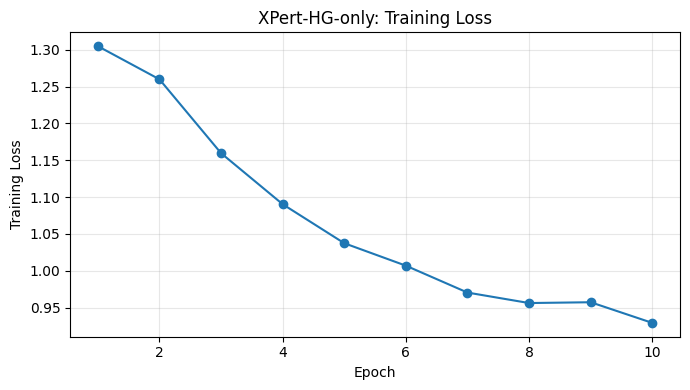

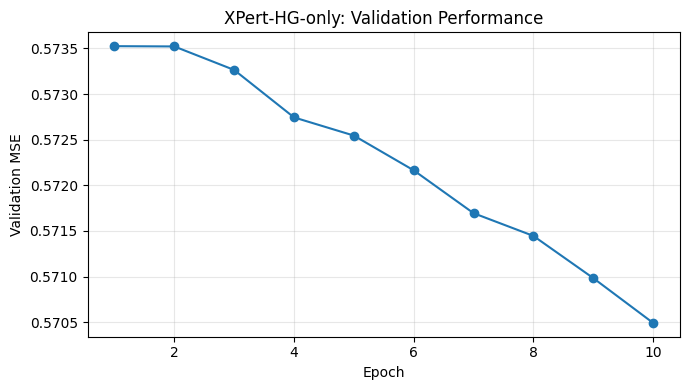

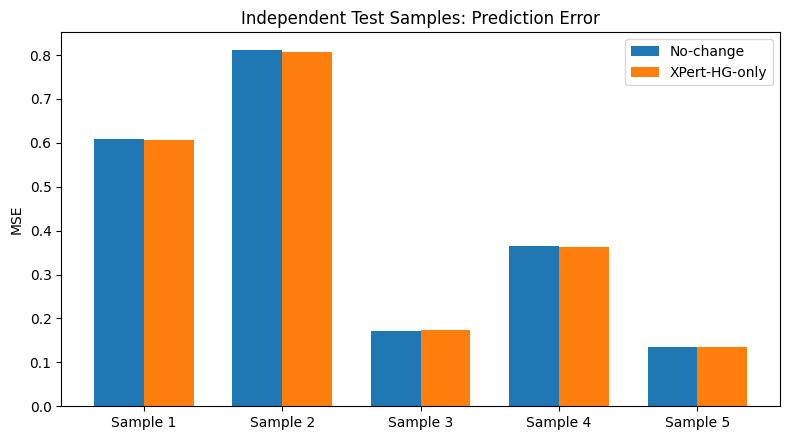

===== Per-sample results =====
 sample  baseline_mse  xpert_mse
      1      0.607858   0.605480
      2      0.811273   0.806851
      3      0.171905   0.173003
      4      0.364986   0.363315
      5      0.136128   0.134203

All three figures saved!


In [13]:
%cd /content/XPert

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out = Path("experiment/course_project")

history = pd.read_csv(out / "training_history.csv")
comparison = pd.read_csv(out / "model_comparison.csv")

with np.load(out / "test_predictions.npz") as data:
    y_true = data["y_true"]
    y_pred = data["y_pred"]
    y_control = data["y_control"]

# Figure 1: Training loss
plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("XPert-HG-only: Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out / "figure1_training_loss.png", dpi=300)
plt.show()

# Figure 2: Validation MSE
plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["val_mse"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("XPert-HG-only: Validation Performance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out / "figure2_validation_mse.png", dpi=300)
plt.show()

# Figure 3: Per-sample test errors
baseline_mse = np.mean((y_true - y_control)**2, axis=1)
xpert_mse = np.mean((y_true - y_pred)**2, axis=1)

sample_results = pd.DataFrame({
    "sample": np.arange(1, len(y_true) + 1),
    "baseline_mse": baseline_mse,
    "xpert_mse": xpert_mse
})
sample_results.to_csv(out / "per_sample_results.csv", index=False)

x = np.arange(len(y_true))
width = 0.36

plt.figure(figsize=(8, 4.5))
plt.bar(x - width/2, baseline_mse, width, label="No-change")
plt.bar(x + width/2, xpert_mse, width, label="XPert-HG-only")
plt.xticks(x, [f"Sample {i+1}" for i in x])
plt.ylabel("MSE")
plt.title("Independent Test Samples: Prediction Error")
plt.legend()
plt.tight_layout()
plt.savefig(out / "figure3_sample_comparison.png", dpi=300)
plt.show()

print("===== Per-sample results =====")
print(sample_results.to_string(index=False))
print("\nAll three figures saved!")

In [14]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = Path("/content/XPert")
destination = Path(
    "/content/drive/MyDrive/AIDD8122_XPert"
)

files_to_save = [
    "experiment/course_project/baseline_results.csv",
    "experiment/course_project/training_history.csv",
    "experiment/course_project/model_comparison.csv",
    "experiment/course_project/test_predictions.npz",
    "experiment/course_project/per_sample_results.csv",
    "experiment/course_project/xpert_hg_best.pt",
    "experiment/course_project/figure1_training_loss.png",
    "experiment/course_project/figure2_validation_mse.png",
    "experiment/course_project/figure3_sample_comparison.png",
    "configs/config_l1000_course_hg.yaml",
    "processed_data/l1000_sdst_course.h5ad",
    "processed_data/course_hg_only_placeholder.npy",
    "models/model_XPert.py",
    "models/model_utils.py",
    "train_xpert.py",
    "utils.py",
    "datasets/__init__.py"
]

for rel in files_to_save:
    src = source / rel
    dst = destination / rel

    if src.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
        print("Saved:", rel)
    else:
        print("Missing:", rel)

print("\nBackup finished!")

Mounted at /content/drive
Saved: experiment/course_project/baseline_results.csv
Saved: experiment/course_project/training_history.csv
Saved: experiment/course_project/model_comparison.csv
Saved: experiment/course_project/test_predictions.npz
Saved: experiment/course_project/per_sample_results.csv
Saved: experiment/course_project/xpert_hg_best.pt
Saved: experiment/course_project/figure1_training_loss.png
Saved: experiment/course_project/figure2_validation_mse.png
Saved: experiment/course_project/figure3_sample_comparison.png
Saved: configs/config_l1000_course_hg.yaml
Saved: processed_data/l1000_sdst_course.h5ad
Saved: processed_data/course_hg_only_placeholder.npy
Saved: models/model_XPert.py
Saved: models/model_utils.py
Saved: train_xpert.py
Saved: utils.py
Saved: datasets/__init__.py

Backup finished!


In [15]:
%cd /content/XPert

import anndata as ad
import numpy as np
import pandas as pd
from pathlib import Path

out = Path("experiment/course_project")

adata = ad.read_h5ad(
    "processed_data/l1000_sdst_course.h5ad"
)

# 1. 检查药物在训练、验证、测试集的分布
print("===== Drug Distribution =====")

drug_table = pd.crosstab(
    adata.obs["pert_id"].astype(str),
    adata.obs["split_course"].astype(str)
)

print(drug_table.to_string())

train_drugs = set(
    adata.obs.loc[
        adata.obs["split_course"] == "train", "pert_id"
    ].astype(str)
)

test_drugs = set(
    adata.obs.loc[
        adata.obs["split_course"] == "test", "pert_id"
    ].astype(str)
)

print("\nTest drugs also in training:",
      len(test_drugs & train_drugs))

print("Test drugs absent from training:",
      len(test_drugs - train_drugs))

# 2. 检查预测的药物诱导表达变化
with np.load(out / "test_predictions.npz") as data:
    y_true = data["y_true"]
    y_pred = data["y_pred"]
    y_control = data["y_control"]

true_delta = y_true - y_control
pred_delta = y_pred - y_control

def safe_pearson(a, b):
    if np.std(a) < 1e-8 or np.std(b) < 1e-8:
        return np.nan
    return np.corrcoef(a, b)[0, 1]

correlations = [
    safe_pearson(a, b)
    for a, b in zip(true_delta, pred_delta)
]

print("\n===== Perturbation Response Evaluation =====")
print("Mean Pearson Delta:", np.nanmean(correlations))
print("Per-sample Pearson Delta:", correlations)

print("Mean absolute true change:",
      np.mean(np.abs(true_delta)))

print("Mean absolute predicted change:",
      np.mean(np.abs(pred_delta)))

pd.DataFrame({
    "sample": np.arange(1, len(correlations) + 1),
    "pearson_delta": correlations
}).to_csv(
    out / "perturbation_response_metrics.csv",
    index=False
)

print("\nEvaluation saved!")

/content/XPert
===== Drug Distribution =====
split_course   test  train  valid
pert_id                          
BRD-A83255679     2      2      0
BRD-K06817181     1      1      3
BRD-K68020183     0      2      1
BRD-K68264559     1      8      0
BRD-K97118047     1      7      1

Test drugs also in training: 4
Test drugs absent from training: 0

===== Perturbation Response Evaluation =====
Mean Pearson Delta: 0.07888167112934903
Per-sample Pearson Delta: [np.float64(0.1016546161364918), np.float64(0.11750888710415812), np.float64(-0.04664237448644417), np.float64(0.07112255188888184), np.float64(0.15076467500365753)]
Mean absolute true change: 0.39588207
Mean absolute predicted change: 0.01728086

Evaluation saved!


In [16]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Available disk space:",
      round(free / 1024**3, 2), "GB")

Available disk space: 112.3 GB


In [18]:
%cd /content/XPert

!wget -c -O /content/processed_data.zip "https://zenodo.org/records/17182939/files/processed_data.zip?download=1"

/content/XPert
--2026-11-09 12:40:31--  https://zenodo.org/records/17182939/files/processed_data.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 188.185.45.63, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 416 REQUESTED_RANGE_NOT_SATISFIABLE

    The file is already fully retrieved; nothing to do.



In [19]:
import zipfile
import shutil
from pathlib import Path

zip_path = Path("/content/processed_data.zip")
output_path = Path(
    "/content/XPert/processed_data/l1000_sdst_78453.h5ad"
)

with zipfile.ZipFile(zip_path) as zf:
    matches = [
        name for name in zf.namelist()
        if name.endswith("l1000_sdst_78453.h5ad")
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one L1000 SDST file; found: {matches}"
        )

    print("Found:", matches[0])

    if not output_path.exists():
        with zf.open(matches[0]) as src:
            with open(output_path, "wb") as dst:
                shutil.copyfileobj(src, dst)

print("Dataset exists:", output_path.exists())
print("Dataset size (GB):",
      round(output_path.stat().st_size / 1024**3, 2))

Found: processed_data/l1000_sdst_78453.h5ad
Dataset exists: True
Dataset size (GB): 1.19


In [20]:
import anndata as ad

adata_full = ad.read_h5ad(
    "/content/XPert/processed_data/l1000_sdst_78453.h5ad",
    backed="r"
)

print("===== Full L1000 Dataset =====")
print("Shape:", adata_full.shape)

print("\nData splits:")
print(adata_full.obs["split_1"].value_counts())

print("\nUnique drugs:",
      adata_full.obs["pert_idx"].nunique())

print("Maximum drug index:",
      adata_full.obs["pert_idx"].max())

print("\nControl expression available:",
      "X_ctl" in adata_full.obsm)

adata_full.file.close()

===== Full L1000 Dataset =====
Shape: (78453, 978)

Data splits:
split_1
train    62762
test     15691
Name: count, dtype: int64

Unique drugs: 8276
Maximum drug index: 8980

Control expression available: True


In [22]:
%cd /content/XPert

import numpy as np
import pandas as pd
import anndata as ad
import yaml
from pathlib import Path
from scipy import sparse

root = Path("/content/XPert")
rng = np.random.default_rng(2026)

# 读取完整数据集
full = ad.read_h5ad(
    root / "processed_data/l1000_sdst_78453.h5ad",
    backed="r"
)

original_split = full.obs["split_1"].astype(str).to_numpy()

train_pool = np.where(original_split == "train")[0]
test_pool = np.where(original_split == "test")[0]

# 从官方训练集抽取1200条，再分为训练1000、验证200
train_valid = rng.choice(
    train_pool, size=1200, replace=False
)

train_indices = train_valid[:1000]
valid_indices = train_valid[1000:]

# 从官方测试集独立抽取200条
test_indices = rng.choice(
    test_pool, size=200, replace=False
)

# 排序索引，兼容 backed h5ad 的读取方式
selected = np.sort(
    np.concatenate([
        train_indices,
        valid_indices,
        test_indices
    ])
)

# 只加载选中的样本到内存
mini = full[selected, :].to_memory()
full.file.close()

# 创建新的数据划分标签
labels = np.full(len(selected), "test", dtype=object)
labels[np.isin(selected, train_indices)] = "train"
labels[np.isin(selected, valid_indices)] = "valid"

mini.obs["split_course_large"] = labels

assert mini.n_obs == 1400
assert mini.n_vars == 978

# 保存数据
dataset_name = "l1000_sdst_course_1400"
dataset_path = root / "processed_data" / f"{dataset_name}.h5ad"

mini.write_h5ad(dataset_path)

print("===== New Dataset =====")
print("Shape:", mini.shape)

print("\nData Split:")
print(mini.obs["split_course_large"].value_counts())

print("\nUnique drugs:", mini.obs["pert_idx"].nunique())

# 检查药物是否在训练集中出现过
train_drugs = set(
    mini.obs.loc[
        mini.obs["split_course_large"] == "train",
        "pert_idx"
    ]
)

test_drugs = set(
    mini.obs.loc[
        mini.obs["split_course_large"] == "test",
        "pert_idx"
    ]
)

print("\nTest drugs seen during training:",
      len(test_drugs & train_drugs))
print("Test drugs unseen during training:",
      len(test_drugs - train_drugs))

print("\nDataset saved:", dataset_path)

/content/XPert
===== New Dataset =====
Shape: (1400, 978)

Data Split:
split_course_large
train    1000
test      200
valid     200
Name: count, dtype: int64

Unique drugs: 1192

Test drugs seen during training: 40
Test drugs unseen during training: 156

Dataset saved: /content/XPert/processed_data/l1000_sdst_course_1400.h5ad


In [23]:
# 1. 读取真实HG特征
hg = np.load(
    root / "HG_data/saved_embedding/HG_drug_embeddings.npy",
    mmap_mode="r"
)

max_drug_idx = int(mini.obs["pert_idx"].max())

assert max_drug_idx < hg.shape[0]

print("HG shape:", hg.shape)
print("Maximum drug index:", max_drug_idx)

# 2. 创建HG-only所需的占位接口
# 不是UniMol特征；wo_unimol=True时模型不使用这些占位特征
placeholder = np.zeros(
    (hg.shape[0], 2, 514),
    dtype=np.float32
)
placeholder[:, 0, 0] = 1

placeholder_path = (
    root / "processed_data/course_hg_only_large_placeholder.npy"
)

np.save(placeholder_path, placeholder)

# 3. 复制之前成功运行的配置
with open("configs/config_l1000_course_hg.yaml") as f:
    config_large = yaml.safe_load(f)

config_large["dataset"]["drug_unimol_path"] = (
    "processed_data/course_hg_only_large_placeholder.npy"
)

config_large["dataset"]["max_atom_size"] = 2
config_large["train"]["batch_size"] = 1
config_large["train"]["num_epochs"] = 10

# 4. 保存独立配置
config_path = (
    root / "configs/config_l1000_course_large.yaml"
)

with open(config_path, "w") as f:
    yaml.safe_dump(config_large, f)

print("\nConfiguration saved:", config_path)
print("Placeholder shape:", placeholder.shape)

HG shape: (8981, 256)
Maximum drug index: 8969

Configuration saved: /content/XPert/configs/config_l1000_course_large.yaml
Placeholder shape: (8981, 2, 514)


In [24]:
# 新数据集的测试样本
test_mask = (
    mini.obs["split_course_large"]
    .astype(str)
    .eq("test")
    .to_numpy()
)

def to_dense(x):
    return x.toarray() if sparse.issparse(x) else np.asarray(x)

y_true_large = to_dense(mini.X[test_mask]).astype("float32")
y_control_large = to_dense(
    mini.obsm["X_ctl"][test_mask]
).astype("float32")

assert y_true_large.shape == (200, 978)
assert y_true_large.shape == y_control_large.shape

baseline_mse = float(
    np.mean((y_true_large - y_control_large) ** 2)
)

baseline_rmse = float(np.sqrt(baseline_mse))
baseline_mae = float(
    np.mean(np.abs(y_true_large - y_control_large))
)

baseline_large = pd.DataFrame([{
    "Model": "No-change Baseline",
    "Samples": len(y_true_large),
    "MSE": baseline_mse,
    "RMSE": baseline_rmse,
    "MAE": baseline_mae
}])

print("===== Large Dataset Baseline =====")
print(baseline_large.to_string(index=False))

output_dir = root / "experiment/course_project_large"
output_dir.mkdir(parents=True, exist_ok=True)

baseline_large.to_csv(
    output_dir / "baseline_large.csv",
    index=False
)

print("\nBaseline saved!")

===== Large Dataset Baseline =====
             Model  Samples      MSE     RMSE      MAE
No-change Baseline      200 0.519923 0.721057 0.442325

Baseline saved!


In [25]:
%cd /content/XPert

import torch
import torch.nn.functional as F
import numpy as np
import yaml
import logging
from pathlib import Path
from types import SimpleNamespace

from utils import load_dataloader
from models.model_XPert import XPertNet

# 确认T4兼容性修改仍然存在
source = Path("models/model_utils.py").read_text()
assert "def flash_attn_func" in source, \
    "T4 attention adaptation is missing"

# 固定随机种子
torch.manual_seed(2026)
np.random.seed(2026)

# 读取新配置
with open("configs/config_l1000_course_large.yaml") as f:
    config_large = yaml.safe_load(f)

config_large["train"]["batch_size"] = 1

args_large = SimpleNamespace(
    model="XPert",
    dataset="l1000_sdst_course_1400",
    drug_feat="unimol",
    pretrained_mode="global",
    mode="train",
    include_cell_idx=True,
    wo_HG=False,
    wo_atom=False,
    wo_atom_HG=False,
    wo_unimol=True,
    wo_ppi=False,
    use_gene_pos_emed=False,
    output_attention=False,
    output_cls_embed=False
)

logger = logging.getLogger("xpert_large")
logger.setLevel(logging.INFO)

device = torch.device("cuda:0")

# 加载1400条数据
train_loader_large, val_loader_large, test_loader_large = load_dataloader(
    args_large,
    config_large,
    logger,
    nfold="split_course_large"
)

print("===== Dataset =====")
print("Train:", len(train_loader_large.dataset))
print("Validation:", len(val_loader_large.dataset))
print("Test:", len(test_loader_large.dataset))

# 创建全新模型，不使用30条演示数据训练的权重
model_large = XPertNet(
    args_large,
    config_large,
    device,
    logger
)

model_large.init_weights()
model_large = model_large.to(device)

print("\nModel initialized successfully!")
print("GPU:", torch.cuda.get_device_name(0))

/content/XPert


INFO:xpert_large:Using 2 atom
INFO:xpert_large:train data:1000
INFO:xpert_large:Valid data:200
INFO:xpert_large:Test data:200
INFO:xpert_large:For dataset l1000_sdst_course_1400, max_value:15.002, min_value:0.0
INFO:xpert_large:Starting load train data...
INFO:xpert_large:binning process... n_bins:128
100%|██████████| 1000/1000 [00:00<00:00, 4528.47it/s]
INFO:xpert_large:Starting load valid data...
INFO:xpert_large:binning process... n_bins:128
100%|██████████| 200/200 [00:00<00:00, 4576.34it/s]
INFO:xpert_large:Starting load test data...
INFO:xpert_large:binning process... n_bins:128
100%|██████████| 200/200 [00:00<00:00, 3605.27it/s]
INFO:xpert_large:train dataloader:1000
INFO:xpert_large:Valid dataloader:200
INFO:xpert_large:Test dataloader:200
INFO:xpert_large:For cell embedding: using ppi_gene_vector + exp embedding
INFO:xpert_large:Using sparse attn: False
INFO:xpert_large:Using sparse attn: False


===== Dataset =====
Train: 1000
Validation: 200
Test: 200

Model initialized successfully!
GPU: Tesla T4


In [26]:
import time
import torch.nn.functional as F

# 与之前演示实验保持相同的简化损失函数
def compute_course_loss(outputs):
    trt_direct = outputs[0]
    ctl_direct = outputs[1]
    delta_pred = outputs[2]
    trt_true = outputs[3]
    ctl_true = outputs[4]

    delta_true = trt_true - ctl_true

    return (
        F.mse_loss(delta_pred, delta_true)
        + 0.2 * F.mse_loss(trt_direct, trt_true)
        + 0.1 * F.mse_loss(ctl_direct, ctl_true)
    )

optimizer_probe = torch.optim.Adam(
    model_large.parameters(),
    lr=0.0001,
    weight_decay=0.00001
)

model_large.train()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start = time.perf_counter()
losses = []

for step, batch in enumerate(train_loader_large):
    if step >= 5:
        break

    optimizer_probe.zero_grad(set_to_none=True)

    outputs = model_large(batch)
    loss = compute_course_loss(outputs)

    assert torch.isfinite(loss), "Invalid loss!"

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model_large.parameters(),
        max_norm=1.0
    )

    optimizer_probe.step()

    losses.append(loss.item())
    print(f"Batch {step + 1}/5 | Loss: {loss.item():.6f}")

torch.cuda.synchronize()

elapsed = time.perf_counter() - start

print("\n===== Training Test =====")
print("Completed batches:", len(losses))
print("Average loss:", np.mean(losses))
print("Elapsed seconds:", round(elapsed, 2))
print(
    "Peak GPU memory (GB):",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2)
)

print("\nLarge Dataset Training Test SUCCESS!")

Batch 1/5 | Loss: 78.735718
Batch 2/5 | Loss: 62.930557
Batch 3/5 | Loss: 57.505192
Batch 4/5 | Loss: 53.201050
Batch 5/5 | Loss: 45.041840

===== Training Test =====
Completed batches: 5
Average loss: 59.48287124633789
Elapsed seconds: 0.67
Peak GPU memory (GB): 0.35

Large Dataset Training Test SUCCESS!


In [27]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)
out_dir.mkdir(parents=True, exist_ok=True)

print("Results directory:", out_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results directory: /content/drive/MyDrive/AIDD8122_XPert/large_run


In [ ]:
%cd /content/XPert

import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from models.model_XPert import XPertNet

# 固定随机种子
random.seed(2026)
np.random.seed(2026)
torch.manual_seed(2026)
torch.cuda.manual_seed_all(2026)

# 创建全新模型，避免使用5批次预训练过的参数
model_final = XPertNet(
    args_large, config_large, device, logger
)
model_final.init_weights()
model_final = model_final.to(device)

optimizer = torch.optim.Adam(
    model_final.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

# 与前期实验保持相同的简化损失函数
def course_loss(outputs):
    trt_direct = outputs[0]
    ctl_direct = outputs[1]
    delta_pred = outputs[2]
    trt_true = outputs[3]
    ctl_true = outputs[4]

    delta_true = trt_true - ctl_true

    return (
        F.mse_loss(delta_pred, delta_true)
        + 0.2 * F.mse_loss(trt_direct, trt_true)
        + 0.1 * F.mse_loss(ctl_direct, ctl_true)
    )

# 使用独立验证集计算预测误差
@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    sum_sq = 0.0
    n_values = 0

    for batch in loader:
        outputs = model(batch)

        y_true = outputs[3]
        y_pred = outputs[4] + outputs[2]

        sum_sq += ((y_true - y_pred) ** 2).sum().item()
        n_values += y_true.numel()

    return sum_sq / n_values

history = []
best_val_mse = float("inf")
best_epoch = 0

for epoch in range(1, 11):
    model_final.train()
    losses = []

    for step, batch in enumerate(train_loader_large, 1):
        optimizer.zero_grad(set_to_none=True)

        outputs = model_final(batch)
        loss = course_loss(outputs)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}, batch {step}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_final.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        losses.append(loss.item())

        if step % 250 == 0:
            print(
                f"Epoch {epoch}/10 | "
                f"Batch {step}/{len(train_loader_large)}",
                flush=True
            )

    train_loss = float(np.mean(losses))
    val_mse = evaluate_mse(model_final, val_loader_large)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_mse": val_mse
    })

    print(
        f"Epoch {epoch:02d}/10 | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val MSE: {val_mse:.6f}",
        flush=True
    )

    # 只根据验证集选择最佳模型
    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch

        torch.save(
            model_final.state_dict(),
            out_dir / "xpert_hg_1400_best.pt"
        )

        print("  Best model updated.", flush=True)

    # 每轮保存训练记录
    pd.DataFrame(history).to_csv(
        out_dir / "training_history_large.csv",
        index=False
    )

print("\n===== Training Complete =====")
print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_mse)
print("Model and history saved!")

INFO:xpert_large:For cell embedding: using ppi_gene_vector + exp embedding
INFO:xpert_large:Using sparse attn: False
INFO:xpert_large:Using sparse attn: False


/content/XPert
Epoch 1/10 | Batch 250/1000
Epoch 1/10 | Batch 500/1000
Epoch 1/10 | Batch 750/1000
Epoch 1/10 | Batch 1000/1000
Epoch 01/10 | Train Loss: 1.986034 | Val MSE: 0.493599
  Best model updated.
Epoch 2/10 | Batch 250/1000
Epoch 2/10 | Batch 500/1000
Epoch 2/10 | Batch 750/1000
Epoch 2/10 | Batch 1000/1000
Epoch 02/10 | Train Loss: 0.815159 | Val MSE: 0.492819
  Best model updated.
Epoch 3/10 | Batch 250/1000
Epoch 3/10 | Batch 500/1000
Epoch 3/10 | Batch 750/1000
Epoch 3/10 | Batch 1000/1000
Epoch 03/10 | Train Loss: 0.768078 | Val MSE: 0.492022
  Best model updated.
Epoch 4/10 | Batch 250/1000
Epoch 4/10 | Batch 500/1000
Epoch 4/10 | Batch 750/1000
Epoch 4/10 | Batch 1000/1000
Epoch 04/10 | Train Loss: 0.748884 | Val MSE: 0.491526
  Best model updated.
Epoch 5/10 | Batch 250/1000
Epoch 5/10 | Batch 500/1000
Epoch 5/10 | Batch 750/1000
Epoch 5/10 | Batch 1000/1000
Epoch 05/10 | Train Loss: 0.735826 | Val MSE: 0.492349
Epoch 6/10 | Batch 250/1000
Epoch 6/10 | Batch 500/1000
E

In [30]:
import pandas as pd
from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)

history_file = out_dir / "training_history_large.csv"
model_file = out_dir / "xpert_hg_1400_best.pt"

print("===== File Check =====")
print("Training history exists:", history_file.exists())
print("Best model exists:", model_file.exists())

if history_file.exists():
    history = pd.read_csv(history_file)

    print("\n===== Training History =====")
    print(history.to_string(index=False))

    print("\n===== Training Status =====")
    print("Completed epochs:", int(history["epoch"].max()))

    best_row = history.loc[history["val_mse"].idxmin()]
    print("Best epoch:", int(best_row["epoch"]))
    print("Best validation MSE:", best_row["val_mse"])

    if history["epoch"].max() == 10:
        print("\nTRAINING COMPLETED!")
    else:
        print("\nTraining stopped before epoch 10.")

if model_file.exists():
    print("\nBest model saved successfully!")
    print("Model size (MB):",
          round(model_file.stat().st_size / 1024**2, 2))

===== File Check =====
Training history exists: True
Best model exists: True

===== Training History =====
 epoch  train_loss  val_mse
     1    1.986034 0.493599
     2    0.815159 0.492819
     3    0.768078 0.492022
     4    0.748884 0.491526
     5    0.735826 0.492349
     6    0.727651 0.491936
     7    0.721333 0.491693
     8    0.716239 0.493245
     9    0.708021 0.492023
    10    0.702134 0.491045

===== Training Status =====
Completed epochs: 10
Best epoch: 10
Best validation MSE: 0.4910449136254246

TRAINING COMPLETED!

Best model saved successfully!
Model size (MB): 21.32


In [31]:
%cd /content/XPert

import numpy as np
import pandas as pd
import torch
from pathlib import Path

# 1. 加载最佳模型
checkpoint = out_dir / "xpert_hg_1400_best.pt"

state = torch.load(
    checkpoint,
    map_location=device,
    weights_only=True
)

model_final.load_state_dict(state)
model_final.eval()

print("Best model loaded successfully!")

# 2. 在测试集上进行预测
true_list = []
pred_list = []
ctl_list = []

with torch.no_grad():
    for batch in test_loader_large:
        outputs = model_final(batch)

        y_true_batch = outputs[3]
        y_ctl_batch = outputs[4]
        y_pred_batch = y_ctl_batch + outputs[2]

        true_list.append(y_true_batch.cpu().numpy())
        pred_list.append(y_pred_batch.cpu().numpy())
        ctl_list.append(y_ctl_batch.cpu().numpy())

y_true = np.concatenate(true_list)
y_pred = np.concatenate(pred_list)
y_ctl = np.concatenate(ctl_list)

print("Prediction shape:", y_pred.shape)

assert y_true.shape == y_pred.shape == y_ctl.shape
assert y_true.shape == (200, 978)
assert np.isfinite(y_pred).all()

# 3. 确认测试集和之前的Baseline一致
baseline_mse = float(np.mean((y_true - y_ctl)**2))

print("Baseline MSE:", baseline_mse)

assert abs(baseline_mse - 0.519923) < 1e-4, \
    "Test data mismatch! Check dataset alignment."

# 4. 获取训练集和测试集的药物ID
train_drugs = set(
    train_loader_large.dataset.raw_data.obs[
        "pert_idx"
    ].astype(int)
)

test_ids = (
    test_loader_large.dataset.raw_data.obs[
        "pert_idx"
    ].astype(int).to_numpy()
)

seen_mask = np.isin(test_ids, list(train_drugs))

# 5. 计算表达变化相关性
def pearson_delta(true, pred, ctl):
    correlations = []

    for yt, yp, yc in zip(true, pred, ctl):
        dt = yt - yc
        dp = yp - yc

        if np.std(dt) < 1e-8 or np.std(dp) < 1e-8:
            continue

        correlations.append(
            np.corrcoef(dt, dp)[0, 1]
        )

    return (
        float(np.mean(correlations))
        if correlations else np.nan
    )

# 6. 定义评价函数
def calculate_metrics(name, group, true, pred, ctl):
    mse = float(np.mean((true - pred)**2))

    return {
        "Group": group,
        "Model": name,
        "N": len(true),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "MAE": float(np.mean(np.abs(true - pred))),
        "Pearson_Delta": pearson_delta(true, pred, ctl),
        "Mean_Abs_Change": float(
            np.mean(np.abs(pred - ctl))
        )
    }

# 7. 总体、已见药物、未见药物分组评价
rows = []

groups = [
    ("All", np.ones(len(y_true), dtype=bool)),
    ("Seen in training", seen_mask),
    ("Unseen in training", ~seen_mask)
]

for group_name, mask in groups:
    if not mask.any():
        continue

    for name, predictions in [
        ("No-change Baseline", y_ctl),
        ("XPert-HG-only", y_pred)
    ]:
        rows.append(calculate_metrics(
            name,
            group_name,
            y_true[mask],
            predictions[mask],
            y_ctl[mask]
        ))

comparison = pd.DataFrame(rows)

print("\n===== FINAL TEST RESULTS =====")
print(comparison.to_string(index=False))

print("\n===== DRUG GROUPS =====")
print("Seen samples:", int(seen_mask.sum()))
print("Unseen samples:", int((~seen_mask).sum()))

# 8. 保存结果到Google Drive
comparison.to_csv(
    out_dir / "model_comparison_large.csv",
    index=False
)

np.savez_compressed(
    out_dir / "test_predictions_large.npz",
    y_true=y_true,
    y_pred=y_pred,
    y_control=y_ctl,
    drug_ids=test_ids,
    seen_mask=seen_mask
)

print("\nFinal evaluation saved successfully!")

/content/XPert
Best model loaded successfully!
Prediction shape: (200, 978)
Baseline MSE: 0.519923210144043

===== FINAL TEST RESULTS =====
             Group              Model   N      MSE     RMSE      MAE  Pearson_Delta  Mean_Abs_Change
               All No-change Baseline 200 0.519923 0.721057 0.442325            NaN         0.000000
               All      XPert-HG-only 200 0.510133 0.714236 0.445866       0.131860         0.074675
  Seen in training No-change Baseline  42 0.554666 0.744759 0.458098            NaN         0.000000
  Seen in training      XPert-HG-only  42 0.544189 0.737692 0.460159       0.136151         0.075890
Unseen in training No-change Baseline 158 0.510688 0.714624 0.438132            NaN         0.000000
Unseen in training      XPert-HG-only 158 0.501079 0.707870 0.442066       0.130719         0.074351

===== DRUG GROUPS =====
Seen samples: 42
Unseen samples: 158

Final evaluation saved successfully!


In [3]:
%cd /content/XPert

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)

history = pd.read_csv(out_dir / "training_history_large.csv")
comparison = pd.read_csv(out_dir / "model_comparison_large.csv")

with np.load(out_dir / "test_predictions_large.npz") as z:
    y_true = z["y_true"]
    y_pred = z["y_pred"]
    y_ctl = z["y_control"]
    seen_mask = z["seen_mask"].astype(bool)

# 图1：训练曲线
plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["train_loss"], marker="o",
         label="Training loss")
plt.plot(history["epoch"], history["val_mse"], marker="s",
         label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("Metric value")
plt.title("XPert-HG-only Training Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "Figure1_Training.png", dpi=300)
plt.show()

# 图2：不同测试组的MSE比较
pivot = comparison.pivot(
    index="Group", columns="Model", values="MSE"
)
pivot = pivot.reindex([
    "All", "Seen in training", "Unseen in training"
])

ax = pivot.plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Test MSE")
ax.set_xlabel("")
ax.set_title("XPert-HG-only vs No-change Baseline")
plt.tight_layout()
plt.savefig(out_dir / "Figure2_Model_Comparison.png", dpi=300)
plt.show()

# 图3：逐样本MSE比较
baseline_error = np.mean((y_true - y_ctl)**2, axis=1)
xpert_error = np.mean((y_true - y_pred)**2, axis=1)

plt.figure(figsize=(6, 5))
plt.scatter(baseline_error, xpert_error, alpha=0.6)

limit = max(baseline_error.max(), xpert_error.max()) * 1.05
plt.plot([0, limit], [0, limit], "--", label="Equal error")

plt.xlabel("No-change Baseline MSE")
plt.ylabel("XPert-HG-only MSE")
plt.title("Per-sample Prediction Errors")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "Figure3_Sample_Errors.png", dpi=300)
plt.show()

# 统计逐样本改善情况
improvement = baseline_error - xpert_error

print("===== Per-sample Analysis =====")
print("Samples improved:",
      int(np.sum(improvement > 0)))
print("Samples worsened:",
      int(np.sum(improvement < 0)))
print("Mean MSE reduction:",
      float(improvement.mean()))
print("Median MSE reduction:",
      float(np.median(improvement)))

print("\nAll figures saved to Google Drive!")

[Errno 2] No such file or directory: '/content/XPert'
/content


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AIDD8122_XPert/large_run/training_history_large.csv'

In [4]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)

print("===== Folder Check =====")
print("Folder exists:", out_dir.exists())

files_to_check = [
    "training_history_large.csv",
    "model_comparison_large.csv",
    "test_predictions_large.npz",
    "xpert_hg_1400_best.pt"
]

print("\n===== Saved Files =====")

for filename in files_to_check:
    filepath = out_dir / filename
    print(
        filename,
        "FOUND" if filepath.exists() else "MISSING"
    )

if out_dir.exists():
    print("\n===== All Files =====")
    for filepath in sorted(out_dir.iterdir()):
        print(filepath.name)
else:
    print("\n===== Possible Project Folders =====")
    root = Path("/content/drive/MyDrive")
    for filepath in root.glob("*XPert*"):
        print(filepath)

===== Folder Check =====
Folder exists: True

===== Saved Files =====
training_history_large.csv FOUND
model_comparison_large.csv FOUND
test_predictions_large.npz FOUND
xpert_hg_1400_best.pt FOUND

===== All Files =====
model_comparison_large.csv
test_predictions_large.npz
training_history_large.csv
xpert_hg_1400_best.pt


Training history loaded: 10 epochs
Test predictions loaded: (200, 978)


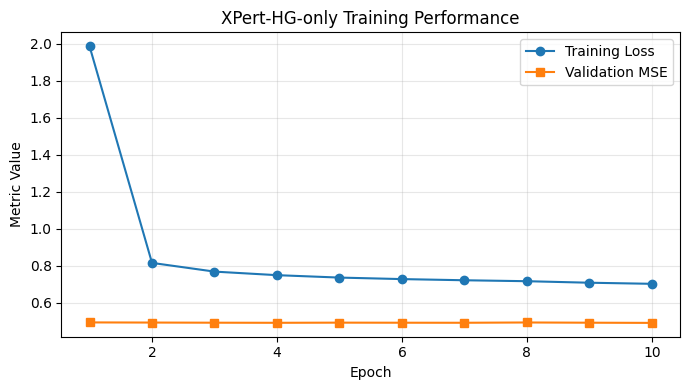

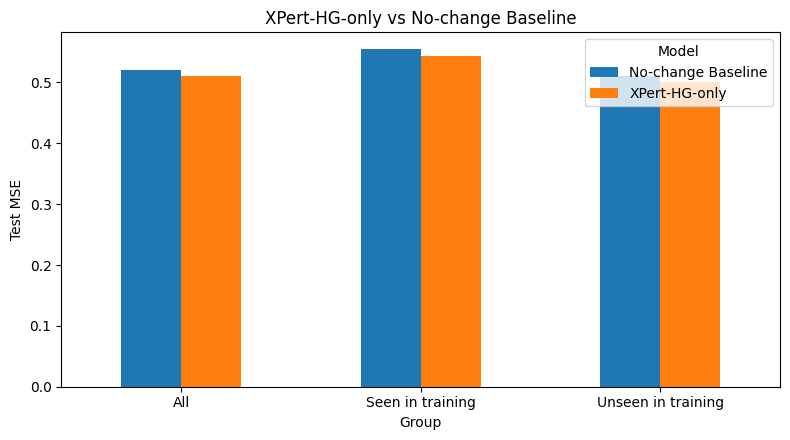

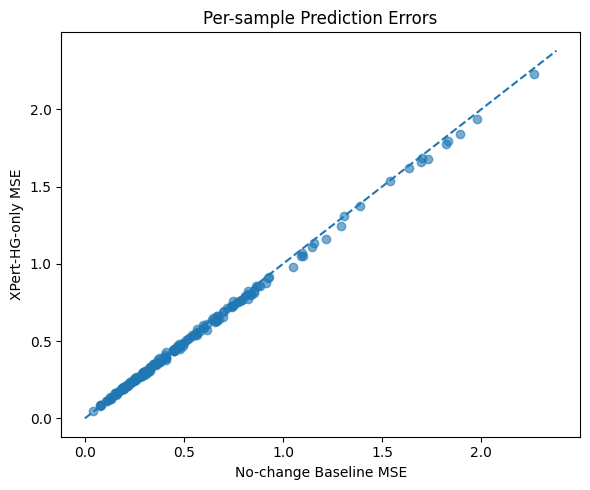


===== Per-sample Analysis =====
Samples improved: 136
Samples worsened: 64
Median MSE improvement: 0.006016343832015991

Three figures saved to Google Drive!


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(
    out_dir / "training_history_large.csv"
)

comparison = pd.read_csv(
    out_dir / "model_comparison_large.csv"
)

with np.load(out_dir / "test_predictions_large.npz") as data:
    y_true = data["y_true"]
    y_pred = data["y_pred"]
    y_ctl = data["y_control"]

print("Training history loaded:", len(history), "epochs")
print("Test predictions loaded:", y_true.shape)

# Figure 1：训练过程
plt.figure(figsize=(7, 4))
plt.plot(
    history["epoch"],
    history["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    history["epoch"],
    history["val_mse"],
    marker="s",
    label="Validation MSE"
)
plt.xlabel("Epoch")
plt.ylabel("Metric Value")
plt.title("XPert-HG-only Training Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "Figure1_Training.png", dpi=300)
plt.show()

# Figure 2：模型比较
pivot = comparison.pivot(
    index="Group",
    columns="Model",
    values="MSE"
)

pivot = pivot.reindex([
    "All",
    "Seen in training",
    "Unseen in training"
])

ax = pivot.plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Test MSE")
ax.set_title("XPert-HG-only vs No-change Baseline")
plt.tight_layout()
plt.savefig(
    out_dir / "Figure2_Model_Comparison.png",
    dpi=300
)
plt.show()

# Figure 3：逐样本误差
baseline_error = np.mean(
    (y_true - y_ctl)**2, axis=1
)

xpert_error = np.mean(
    (y_true - y_pred)**2, axis=1
)

plt.figure(figsize=(6, 5))
plt.scatter(baseline_error, xpert_error, alpha=0.6)

limit = max(
    baseline_error.max(),
    xpert_error.max()
) * 1.05

plt.plot([0, limit], [0, limit], "--")
plt.xlabel("No-change Baseline MSE")
plt.ylabel("XPert-HG-only MSE")
plt.title("Per-sample Prediction Errors")
plt.tight_layout()
plt.savefig(
    out_dir / "Figure3_Sample_Errors.png",
    dpi=300
)
plt.show()

print("\n===== Per-sample Analysis =====")
print("Samples improved:", int((xpert_error < baseline_error).sum()))
print("Samples worsened:", int((xpert_error > baseline_error).sum()))
print("Median MSE improvement:",
      float(np.median(baseline_error - xpert_error)))

print("\nThree figures saved to Google Drive!")

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)

with np.load(out_dir / "test_predictions_large.npz") as z:
    y_true = z["y_true"]
    y_pred = z["y_pred"]
    y_ctl = z["y_control"]
    drug_ids = z["drug_ids"]

# 每个测试样本的MSE
baseline_mse = np.mean(
    (y_true - y_ctl)**2, axis=1
)

xpert_mse = np.mean(
    (y_true - y_pred)**2, axis=1
)

# 正数表示XPert优于Baseline
improvement = baseline_mse - xpert_mse

print("===== Improvement Analysis =====")
print("Samples:", len(improvement))
print("Mean improvement:", improvement.mean())
print("Median improvement:", np.median(improvement))
print("Improved samples:", np.sum(improvement > 0))

# 按药物ID进行聚类Bootstrap
# 避免简单地把同一药物的重复样本视为完全独立
unique_drugs, group_idx = np.unique(
    drug_ids, return_inverse=True
)

group_sum = np.bincount(
    group_idx, weights=improvement
)
group_count = np.bincount(group_idx)

rng = np.random.default_rng(2026)
n_boot = 5000
n_groups = len(unique_drugs)

sampled = rng.integers(
    0, n_groups,
    size=(n_boot, n_groups)
)

boot_mean = (
    group_sum[sampled].sum(axis=1) /
    group_count[sampled].sum(axis=1)
)

ci_low, ci_high = np.percentile(
    boot_mean, [2.5, 97.5]
)

print("\n===== Bootstrap Results =====")
print("Unique test drugs:", n_groups)
print("Mean MSE reduction:", improvement.mean())
print("95% CI:", ci_low, "to", ci_high)

# 保存结果
pd.DataFrame([{
    "Mean_MSE_Improvement": improvement.mean(),
    "CI_Lower": ci_low,
    "CI_Upper": ci_high,
    "N_Test_Samples": len(improvement),
    "N_Test_Drugs": n_groups
}]).to_csv(
    out_dir / "bootstrap_results.csv",
    index=False
)

print("\nBootstrap results saved!")

===== Improvement Analysis =====
Samples: 200
Mean improvement: 0.009790651
Median improvement: 0.006016344
Improved samples: 136

===== Bootstrap Results =====
Unique test drugs: 196
Mean MSE reduction: 0.009790651
95% CI: 0.007555781088917706 to 0.012155199146815222

Bootstrap results saved!


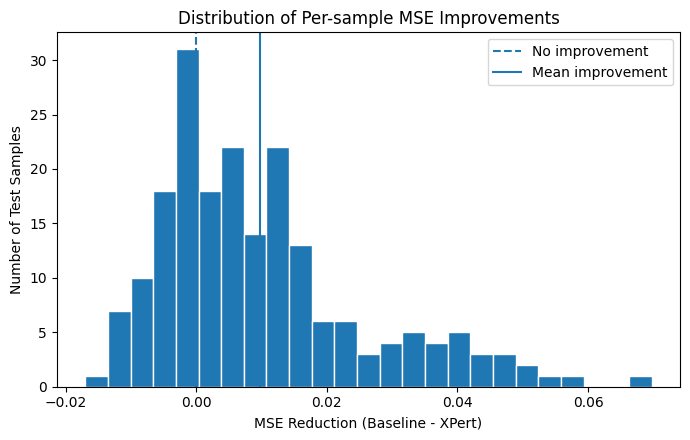

Figure 4 saved!


In [8]:
plt.figure(figsize=(7, 4.5))

plt.hist(improvement, bins=25, edgecolor="white")
plt.axvline(
    0,
    linestyle="--",
    label="No improvement"
)
plt.axvline(
    improvement.mean(),
    linestyle="-",
    label="Mean improvement"
)

plt.xlabel("MSE Reduction (Baseline - XPert)")
plt.ylabel("Number of Test Samples")
plt.title("Distribution of Per-sample MSE Improvements")
plt.legend()
plt.tight_layout()

plt.savefig(
    out_dir / "Figure4_Improvement_Distribution.png",
    dpi=300
)
plt.show()

print("Figure 4 saved!")

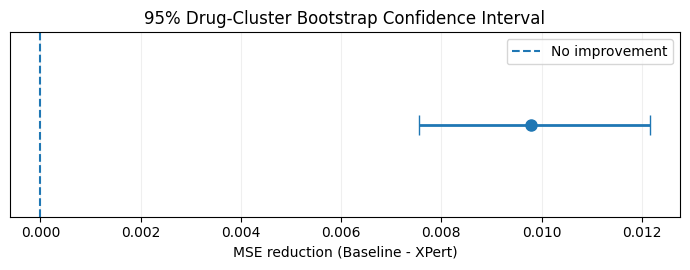

Mean MSE improvement: 0.009791
95% CI: 0.007556 to 0.012155
Figure and results table saved!


In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

out_dir = Path(
    "/content/drive/MyDrive/AIDD8122_XPert/large_run"
)

bootstrap = pd.read_csv(out_dir / "bootstrap_results.csv")
comparison = pd.read_csv(out_dir / "model_comparison_large.csv")

mean = float(bootstrap["Mean_MSE_Improvement"].iloc[0])
lower = float(bootstrap["CI_Lower"].iloc[0])
upper = float(bootstrap["CI_Upper"].iloc[0])

# Figure 5: Bootstrap confidence interval
fig, ax = plt.subplots(figsize=(7, 2.8))

ax.errorbar(
    mean, 0,
    xerr=[[mean - lower], [upper - mean]],
    fmt="o",
    capsize=7,
    markersize=8,
    linewidth=2
)

ax.axvline(0, linestyle="--", label="No improvement")
ax.set_yticks([])
ax.set_xlabel("MSE reduction (Baseline - XPert)")
ax.set_title("95% Drug-Cluster Bootstrap Confidence Interval")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.savefig(
    out_dir / "Figure5_Bootstrap_CI.png", dpi=300
)
plt.show()

# 保存可直接用于报告的最终实验汇总
comparison.to_csv(
    out_dir / "Final_Results_Table.csv", index=False
)

print("Mean MSE improvement:", round(mean, 6))
print("95% CI:", round(lower, 6), "to", round(upper, 6))
print("Figure and results table saved!")